In [30]:
import numpy as np
import imageio
import os
import torch
from torch.utils.data import Dataset
from torchvision import transforms
from utils.read_write_model import read_images_binary, read_cameras_binary, read_points3D_binary, qvec2rotmat

transform = transforms.ToTensor()
image_dir = "/home/yuzhou/Desktop/datasets/nerf_synthetic/nerf_synthetic_colmap/chair/train/"
path = sorted([
os.path.join(image_dir, f) for f in os.listdir(image_dir) if f.endswith(('JPG', 'jpg', 'png'))
            ])
images = [transform(imageio.imread(p)) for p in path]

/tmp/ipykernel_951688/1014628021.py:14: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [transform(imageio.imread(p)) for p in path]


In [37]:
paths = sorted(
    [os.path.join(image_dir, f)
     for f in os.listdir(image_dir)
     if f.endswith(('JPG', 'jpg', 'png'))],
    key=lambda p: int(os.path.basename(p).split('_')[1].split('.')[0])
)

from utils.read_write_model import *
colmap_dir = "/home/yuzhou/Desktop/datasets/nerf_synthetic/nerf_synthetic_colmap/chair/colmap_results/triangulated/"
images = read_images_binary(os.path.join(colmap_dir, "images.bin"))
cameras = read_cameras_binary(os.path.join(colmap_dir, "cameras.bin"))

image_ids_sorted = sorted(images.keys())
image_ids_sorted
images 

{97: Image(id=97, qvec=array([ 0.14901004,  0.19612105,  0.77171321, -0.58633716]), tvec=array([-0.      , -0.      ,  4.031129]), camera_id=1, name='r_96.png', xys=array([[522.1137085 , 101.02696991],
        [535.50469971, 108.35958862],
        [509.10202026, 113.27497101],
        ...,
        [640.72418213, 412.71087646],
        [234.85884094, 492.96414185],
        [463.33282471, 616.78881836]], shape=(890, 2)), point3D_ids=array([   -1,    -1,    -1,    -1,    -1,  8112, 28438,    -1,    -1,
        10992,    -1,    -1,    -1,    -1,  8115,    -1,  8196,    -1,
           -1,    -1,    -1,    -1, 31030,    -1,    -1,    -1,    -1,
           -1,    -1,    -1,    -1, 22567,    -1,    -1,    -1, 22593,
         2976,    -1,    -1,    -1,    -1,    -1,    -1,    -1,    -1,
           -1, 28655, 31020, 19347,    -1,    -1,    -1, 22714,    -1,
        24425,    -1,    -1,    -1,    -1,    -1,  8127, 22711,    -1,
         8124, 29520,    -1,    -1,    -1, 28622, 31137,    -1,  8128

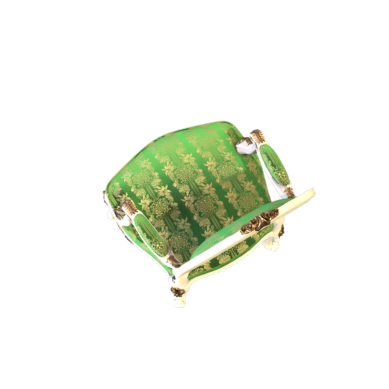

torch.Size([4, 800, 800])


In [31]:
import matplotlib.pyplot as plt

idx=50
img = images[idx].cpu()

plt.imshow(img.permute(1, 2, 0))
plt.axis('off')
plt.show()

print(img.shape)

In [25]:
img[0][0:20,0:20]

tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0